# 12 — Results summary: Part D and combined Part B + Part D (2019–2023)

Reads the fold-level results written by Notebooks 08 and 11, and turns them into tables and figures with 95% confidence intervals. Nothing is retrained. Figures are also saved as PNG under `results/figures/` for slides and the thesis.

## Approach

| Step | Notebook | What it does |
|---|---|---|
| Part D aggregation | (Aug) | Part D *by Provider and Drug* → one row per NPI + year: 5 fields × 6 stats = 30 features (**A**) |
| Part D labels | 07 | Same cumulative LEIE table and rule as Part B (Notebook 04): `year < last_excl_year` |
| Part D enrichment | 09 | + 50 *by Provider* features (Rahi's files) → **SbP** alone, **AE** = A + SbP |
| Part D baseline | 08 | Paper protocol: 6 runs × 5 folds, k-fold-by-NPI, XGB depth 4, RF depth 16, threshold = training prior |
| Combined dataset | 10 | Outer join of Part B AE and Part D AE on NPI + year; NaN where a provider is absent; labels re-derived and checked against both programs |
| Combined baseline | 11 | Same protocol, XGB; three feature sets (**B**, **D**, **BD**), scored overall and per provider group |

## Label definitions compared

| Label | Positives | Why |
|---|---|---|
| `fraud` | Paper rule, all fraud-related LEIE exclusion types present (1128 a1, a2, a3, b4, b7) | Replication |
| `fraud_h2` | Only rows whose exclusion is ≤ 2 years after the claim year | Right-censoring / label look-ahead check |
| `fraud_nob4` | Excludes 1128(b)(4) license revocations (~35% of fraud providers) | License actions often have no billing footprint |

In Notebook 10/11 (combined), rows removed from a label are dropped, not relabeled 0. In Notebook 07/08 (Part D alone), `fraud_h2` relabeled them 0 (affects < 0.1% of negatives).

**Metrics.** AUC (ranking quality, 0.5 = random). AUPRC (precision–recall; base rate ≈ fraud rate, so it is also shown as × better than random). Accuracy is not used: with ~0.05% fraud, predicting "not fraud" for everyone scores 99.95%.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(os.environ.get("DATA_DIR", "/scratch/sm3664/medicare-fraud"))
RES = DATA_DIR / "results"
FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)

LABEL_NAME  = {"fraud": "Paper labels", "fraud_h2": "Exclusion ≤ 2 yrs", "fraud_nob4": "No license revocations (b4)"}
LABEL_COLOR = {"fraud": "#2F5D8A", "fraud_h2": "#9DB9D5", "fraud_nob4": "#D9822B"}
FEAT_COLOR  = {"B": "#9DB9D5", "D": "#6C8EB0", "BD": "#D9822B", "SbP": "#9DB9D5", "A": "#6C8EB0", "AE": "#2F5D8A"}
GROUP_NAME  = {"all": "All providers", "both": "In both programs", "B_only": "Part B only", "D_only": "Part D only"}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3})

def summarize(df, by, metric="AUC"):
    g = df.groupby(by)[metric]
    s = g.agg(mean="mean", sd="std", n="count").reset_index()
    s["half"] = 1.96 * s.sd / np.sqrt(s.n)
    s["lo"], s["hi"] = s["mean"] - s.half, s["mean"] + s.half
    return s

def fmt(s, metric_digits=3):
    return s.assign(**{"95% CI": s.apply(lambda r: f"{r.lo:.{metric_digits}f}–{r.hi:.{metric_digits}f}", axis=1),
                       "mean": s["mean"].round(metric_digits)}).drop(columns=["sd", "half", "lo", "hi"])

def bars(ax, s, x_col, hue_col, x_order, hue_order, colors, hue_names=None, x_names=None, ylim=(0.5, 0.9)):
    w = 0.8 / len(hue_order)
    for j, h in enumerate(hue_order):
        sub = s[s[hue_col] == h].set_index(x_col).reindex(x_order)
        xs = np.arange(len(x_order)) + (j - (len(hue_order) - 1) / 2) * w
        ax.bar(xs, sub["mean"], w * 0.92, color=colors[h], label=(hue_names or {}).get(h, h),
               yerr=sub["half"], capsize=3, error_kw={"elinewidth": 1, "ecolor": "#333333"})
        for x, m in zip(xs, sub["mean"]):
            if pd.notna(m):
                ax.text(x, m + 0.008, f"{m:.3f}", ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks(np.arange(len(x_order)), [(x_names or {}).get(x, x) for x in x_order])
    ax.set_ylim(*ylim)
    ax.axhline(0.5, color="#999999", lw=0.8)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved", FIG / f"{name}.png")

## 1. Load fold-level results

In [2]:
def read(p):
    p = RES / p
    return pd.read_csv(p) if p.exists() else None

# Part D: the AE runs hold SbP, A and AE on the same folds; fall back to the A-only runs.
pd_parts = []
for lab in ["fraud", "fraud_h2"]:
    r = read(f"part_d/nb08_AE_{lab}_fold_results.csv")
    if r is None:
        r = read(f"part_d/nb08_{lab}_fold_results.csv")
    if r is not None:
        pd_parts.append(r.assign(label=lab))
part_d = pd.concat(pd_parts, ignore_index=True)

combined = pd.concat([r for lab in ["fraud", "fraud_h2", "fraud_nob4"]
                      if (r := read(f"combined/nb11_{lab}_fold_results.csv")) is not None], ignore_index=True)

print("Part D rows:", len(part_d), "| folds per (label, dataset, learner):",
      part_d.groupby(["label", "dataset", "learner"]).size().unique())
print("Combined rows:", len(combined), "| folds per (label, dataset, group):",
      combined.groupby(["label", "dataset", "group"]).size().unique())

Part D rows: 360 | folds per (label, dataset, learner): [30]
Combined rows: 1080 | folds per (label, dataset, group): [30]


## 2. Part D: does enrichment help?

SbP = CMS *by Provider* features only; A = aggregated drug-level statistics; AE = both. Bars are means over 30 folds, error bars are 95% CIs.

95% CI                mean       
learner                    RF          XGB     RF    XGB
label    dataset                                        
fraud    A        0.707–0.722  0.737–0.748  0.714  0.742
         AE       0.731–0.746  0.750–0.761  0.739  0.756
         SbP      0.738–0.750  0.746–0.756  0.744  0.751
fraud_h2 A        0.715–0.729  0.737–0.749  0.722  0.743
         AE       0.729–0.742  0.761–0.774  0.735  0.767
         SbP      0.732–0.745  0.744–0.758  0.739  0.751

saved /scratch/sm3664/medicare-fraud/results/figures/fig1_partd_datasets.png


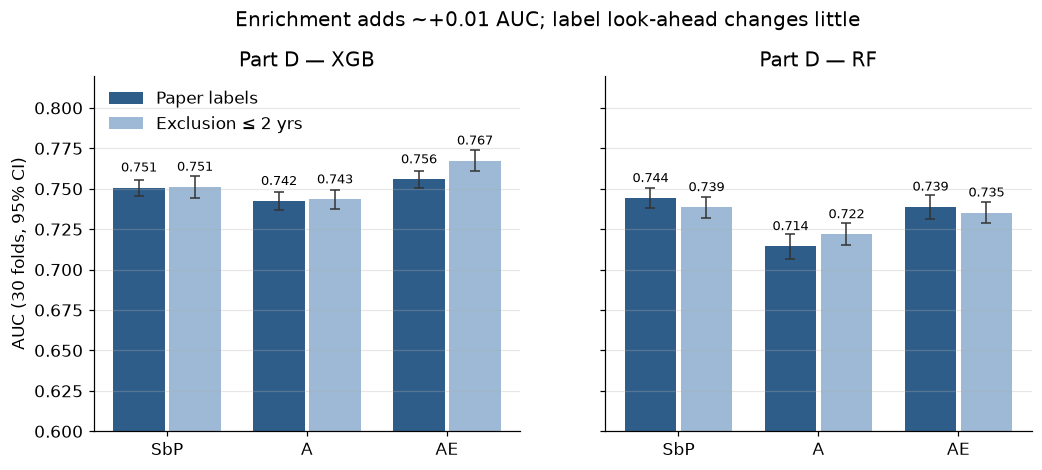

In [3]:
s = summarize(part_d, ["label", "learner", "dataset"])
display(fmt(s).pivot_table(index=["label", "dataset"], columns="learner", values=["mean", "95% CI"], aggfunc="first"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, lr in zip(axes, ["XGB", "RF"]):
    bars(ax, s[s.learner == lr], "dataset", "label", ["SbP", "A", "AE"], ["fraud", "fraud_h2"],
         LABEL_COLOR, LABEL_NAME, ylim=(0.6, 0.82))
    ax.set_title(f"Part D — {lr}")
axes[0].set_ylabel("AUC (30 folds, 95% CI)")
axes[0].legend(loc="upper left", frameon=False)
fig.suptitle("Enrichment adds ~+0.01 AUC; label look-ahead changes little", y=1.02)
save(fig, "fig1_partd_datasets")
plt.show()

## 3. Combined Part B + Part D: which label definition matters?

B+D features, XGB. Scored on all providers and separately on each provider group.

group,all,both,B_only,D_only
label,,,,
fraud,0.763,0.769,0.710,0.765
fraud_h2,0.797,0.784,0.716,0.777
fraud_nob4,0.804,0.814,0.776,0.792


saved /scratch/sm3664/medicare-fraud/results/figures/fig2_combined_labels.png


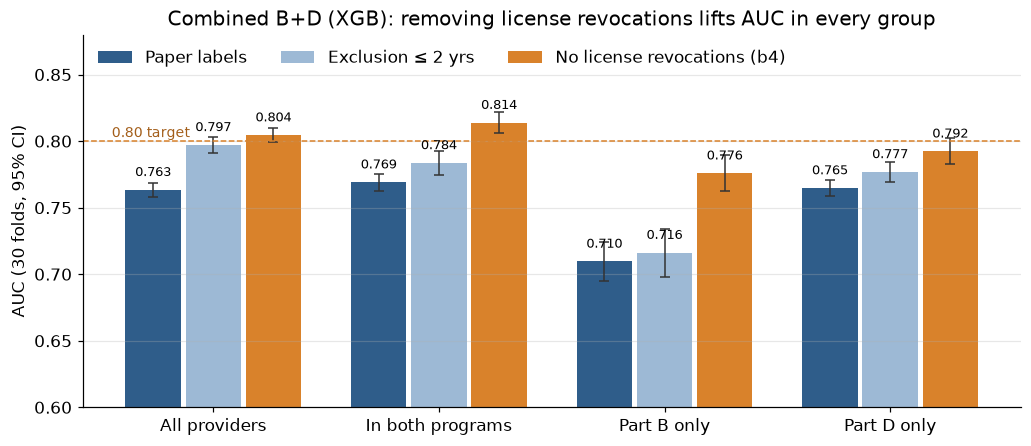

In [4]:
bd = combined[(combined.dataset == "BD") & (combined.learner == "XGB")]
s = summarize(bd, ["label", "group"])
display(fmt(s).pivot_table(index="label", columns="group", values="mean", aggfunc="first")
        .reindex(columns=["all", "both", "B_only", "D_only"]))

fig, ax = plt.subplots(figsize=(11, 4.4))
bars(ax, s, "group", "label", ["all", "both", "B_only", "D_only"], ["fraud", "fraud_h2", "fraud_nob4"],
     LABEL_COLOR, LABEL_NAME, GROUP_NAME, ylim=(0.6, 0.88))
ax.axhline(0.80, color="#D9822B", lw=1, ls="--")
ax.text(-0.45, 0.803, "0.80 target", color="#A35E1A", fontsize=9, ha="left")
ax.set_ylabel("AUC (30 folds, 95% CI)")
ax.set_title("Combined B+D (XGB): removing license revocations lifts AUC in every group")
ax.legend(loc="upper left", frameon=False, ncol=3)
save(fig, "fig2_combined_labels")
plt.show()

### Check: is the overall AUC inflated by the group mix?

Overall AUC pools providers from all groups. If it is **higher than every group's AUC**, part of it comes from separating the groups (e.g., "bills in both programs" vs "Part B only") rather than ranking providers within a group. In that case, compare labels **within** groups.

In [5]:
w = s.pivot_table(index="label", columns="group", values="mean")
w["max_group"] = w[["both", "B_only", "D_only"]].max(axis=1)
w["all_above_every_group"] = w["all"] > w["max_group"]
display(w.round(4))
for lab, row in w.iterrows():
    if row.all_above_every_group:
        print(f"⚠ {LABEL_NAME[lab]}: overall AUC {row['all']:.3f} exceeds every group "
              f"(max {row.max_group:.3f}) — the overall gain is partly a group-mix effect.")

base = w.loc["fraud"]
gain = (w[["all", "both", "B_only", "D_only"]] - base[["all", "both", "B_only", "D_only"]]).round(3)
print("\nAUC change vs paper labels:")
display(gain)

group,B_only,D_only,all,both,max_group,all_above_every_group
label,,,,,,
fraud,0.7095,0.7647,0.7634,0.7691,0.7691,False
fraud_h2,0.7161,0.7768,0.7971,0.7836,0.7836,True
fraud_nob4,0.7758,0.7923,0.8044,0.8138,0.8138,False


⚠ Exclusion ≤ 2 yrs: overall AUC 0.797 exceeds every group (max 0.784) — the overall gain is partly a group-mix effect.

AUC change vs paper labels:


group,all,both,B_only,D_only
label,,,,
fraud,0.0,0.0,0.0,0.0
fraud_h2,0.033754,0.01448,0.006602,0.012138
fraud_nob4,0.04106,0.044712,0.06627,0.027628


## 4. Combined: does seeing both programs help?

Restricted to providers who appear in **both** Part B and Part D, scored with billing features only (B), prescribing only (D), or both (BD). Same rows and folds within each label.

dataset,B,D,BD
label,,,
fraud,0.758,0.745,0.769
fraud_h2,0.774,0.748,0.784
fraud_nob4,0.809,0.775,0.814


saved /scratch/sm3664/medicare-fraud/results/figures/fig3_combined_features_both.png


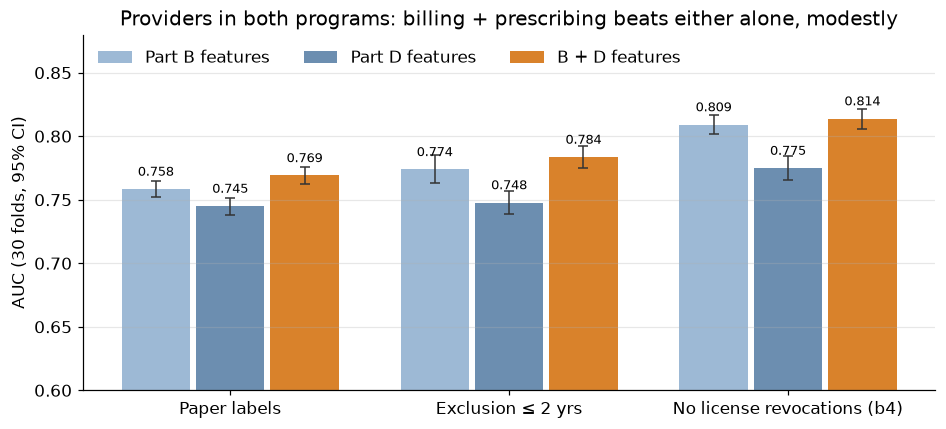

In [6]:
both = combined[(combined.group == "both") & (combined.learner == "XGB")]
s = summarize(both, ["label", "dataset"])
display(fmt(s).pivot_table(index="label", columns="dataset", values="mean", aggfunc="first")[["B", "D", "BD"]])

fig, ax = plt.subplots(figsize=(10, 4.2))
bars(ax, s, "label", "dataset", ["fraud", "fraud_h2", "fraud_nob4"], ["B", "D", "BD"],
     FEAT_COLOR, {"B": "Part B features", "D": "Part D features", "BD": "B + D features"},
     LABEL_NAME, ylim=(0.6, 0.88))
ax.set_ylabel("AUC (30 folds, 95% CI)")
ax.set_title("Providers in both programs: billing + prescribing beats either alone, modestly")
ax.legend(loc="upper left", frameon=False, ncol=3)
save(fig, "fig3_combined_features_both")
plt.show()

## 5. Fold-to-fold stability

Each dot is one of the 30 folds (B+D features, all providers). Tight clusters mean the differences between labels are not noise.

saved /scratch/sm3664/medicare-fraud/results/figures/fig4_fold_stability.png


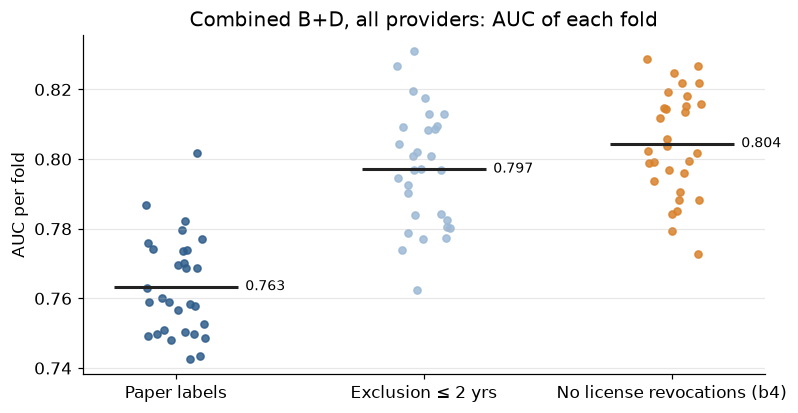

In [7]:
rng = np.random.default_rng(0)
labs = [l for l in ["fraud", "fraud_h2", "fraud_nob4"] if l in set(bd.label)]
fig, ax = plt.subplots(figsize=(8, 4))
for i, lab in enumerate(labs):
    v = bd[(bd.label == lab) & (bd.group == "all")].AUC.to_numpy()
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=22, color=LABEL_COLOR[lab], alpha=0.85)
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color="#222222", lw=2)
    ax.text(i + 0.28, v.mean(), f"{v.mean():.3f}", va="center", fontsize=9)
ax.set_xticks(range(len(labs)), [LABEL_NAME[l] for l in labs])
ax.set_ylabel("AUC per fold")
ax.set_title("Combined B+D, all providers: AUC of each fold")
save(fig, "fig4_fold_stability")
plt.show()

## 6. AUPRC: how much better than random?

AUPRC depends on the fraud rate, so it is divided by each test fold's base rate (× better than random guessing). Combined B+D, XGB.

In [8]:
c = combined[combined.learner == "XGB"].assign(lift=lambda d: d.AUPRC / d.base_rate)
t = c.groupby(["label", "dataset", "group"])[["AUPRC", "base_rate", "lift"]].mean().reset_index()
display(t[t.group == "all"].pivot_table(index="label", columns="dataset", values="lift").round(1)
        .rename(columns=lambda x: f"{x} (× random)"))

dataset,B (× random),BD (× random),D (× random)
label,,,
fraud,4.4,7.2,5.7
fraud_h2,6.2,9.7,9.6
fraud_nob4,7.9,11.4,8.2


## 7. All headline results

Best XGB result per setup. Part B (Notebook 06) is from 10-fold CV with 1:1 undersampling, so its interval is wider and it is not on the same folds. The reference paper's Part B AE result (2013–2019) is shown for scale.

,setup,mean,lo,hi
0,"Part B, paper labels (NB06)",0.765,0.742,0.787
1,"Part D AE, paper labels",0.756,0.750,0.761
2,"Part D AE, exclusion ≤ 2 yrs",0.767,0.761,0.774
3,"Combined B+D, paper labels",0.763,0.758,0.768
4,"Combined B+D, exclusion ≤ 2 yrs*",0.797,0.791,0.803
5,"Combined B+D, no license revocations",0.804,0.799,0.810


saved /scratch/sm3664/medicare-fraud/results/figures/fig5_headline.png


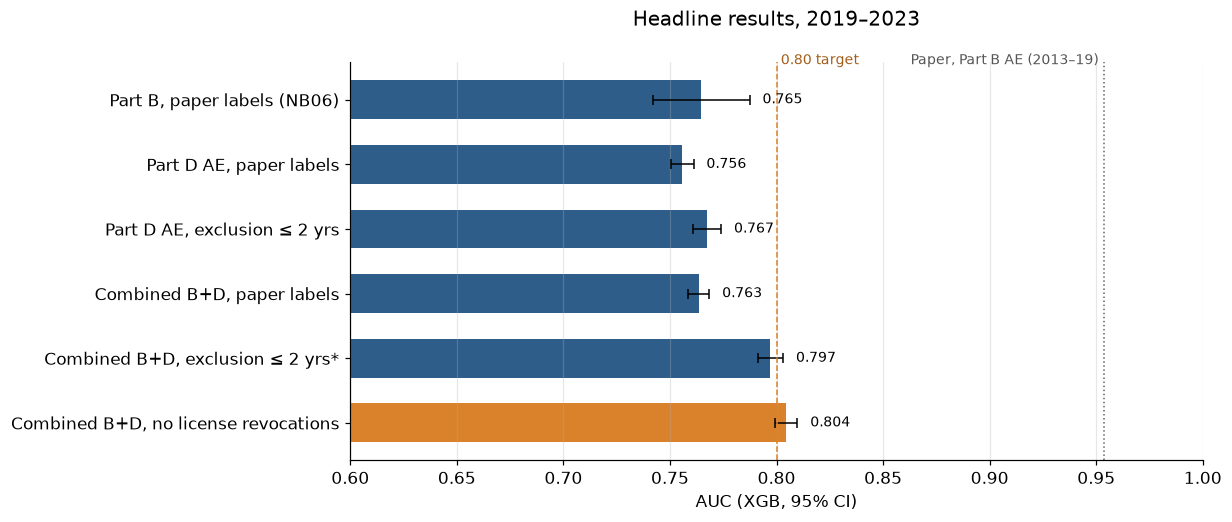

* overall AUC partly reflects the group mix (see section 3); within-group gain ≈ +0.01


In [9]:
rows = [("Part B, paper labels (NB06)", 0.7647, 0.7421, 0.7874)]
pdx = summarize(part_d[part_d.learner == "XGB"], ["label", "dataset"])
for lab, name in [("fraud", "Part D AE, paper labels"), ("fraud_h2", "Part D AE, exclusion ≤ 2 yrs")]:
    r = pdx[(pdx.label == lab) & (pdx.dataset == "AE")]
    if len(r): rows.append((name, *r[["mean", "lo", "hi"]].iloc[0]))
bdx = summarize(bd[bd.group == "all"], ["label"])
for lab, name in [("fraud", "Combined B+D, paper labels"), ("fraud_h2", "Combined B+D, exclusion ≤ 2 yrs*"),
                  ("fraud_nob4", "Combined B+D, no license revocations")]:
    r = bdx[bdx.label == lab]
    if len(r): rows.append((name, *r[["mean", "lo", "hi"]].iloc[0]))
head = pd.DataFrame(rows, columns=["setup", "mean", "lo", "hi"])
display(head.round(3))

fig, ax = plt.subplots(figsize=(10, 0.55 * len(head) + 1.4))
y = np.arange(len(head))[::-1]
cols = ["#D9822B" if "no license" in s_ else "#2F5D8A" for s_ in head.setup]
ax.barh(y, head["mean"], color=cols, height=0.6,
        xerr=[head["mean"] - head.lo, head.hi - head["mean"]], capsize=3, error_kw={"elinewidth": 1})
for yi, m, hi in zip(y, head["mean"], head.hi):
    ax.text(hi + 0.006, yi, f"{m:.3f}", va="center", fontsize=9)
ax.set_yticks(y, head.setup)
ax.axvline(0.80, color="#D9822B", lw=1, ls="--"); ax.text(0.802, y.max() + 0.55, "0.80 target", color="#A35E1A", fontsize=9)
ax.axvline(0.9536, color="#666666", lw=1, ls=":"); ax.text(0.951, y.max() + 0.55, "Paper, Part B AE (2013–19)", color="#555555", fontsize=9, ha="right")
ax.set_xlim(0.6, 1.0); ax.set_xlabel("AUC (XGB, 95% CI)")
ax.grid(axis="x", alpha=0.3); ax.grid(axis="y", visible=False)
ax.set_title("Headline results, 2019–2023", pad=24)
save(fig, "fig5_headline")
plt.show()
print("* overall AUC partly reflects the group mix (see section 3); within-group gain ≈ +0.01")

## 8. Findings

1. **License revocations are the main label problem.** Removing 1128(b)(4) positives raises combined B+D AUC from about 0.76 to about 0.80, and the gain holds within every provider group. These providers are excluded for state licensing actions that usually leave no trace in billing.
2. **Label look-ahead matters little.** Keeping only positives within 2 years of exclusion changes AUC by about +0.01 within groups. Fraud counts fall toward 2023 (right-censoring), but AUC by year does not.
3. **Enrichment helps modestly.** In Part D, adding *by Provider* features (AE) adds about +0.01 over A; SbP alone beats A.
4. **Combining programs helps modestly.** For providers in both programs, billing + prescribing beats either alone by about +0.01, and the combined set has more fraud providers than either program.
5. **The models are untuned.** All results use the paper's default XGB/RF settings, with no peer-normalized, code-mix or trend features.

**Caveats.** (a) `fraud_nob4` is a narrower definition of fraud, not a better score on the same task; report it beside the paper-label result. (b) Overall AUC can be inflated by the group mix (section 3). (c) The gap to the paper (~0.95) is still unexplained; the 2013–2019 rebuild is the test for era vs pipeline.

**Open decisions (Prof. Dehzangi).** Which label is primary (`fraud` vs `fraud_nob4`, or both reported); whether to apply the 2-year horizon; whether to run the 2013–2019 replication before further modeling.